In [1]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')




In [2]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "nf-core-mlomix-bimodal/finalize")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")

In [3]:
data <- function(gex_file, dnam_file, labels_file) {
    # --- Read in data ---
    X_gex  <- read.csv(gex_file,    row.names = 1, check.names = FALSE)
    X_dnam <- read.csv(dnam_file,   row.names = 1, check.names = FALSE)
    labels <- read.csv(labels_file, row.names = 1)

    # --- Extract Y as a factor ---
    # Replace "subtype" with your actual column name
    Y <- factor(labels[, "class"])

    # --- Align sample order across all three ---
    # (critical — mixOmics assumes rows are in the same order)
    common_samples <- Reduce(intersect, list(rownames(X_gex),
                                            rownames(X_dnam),
                                            rownames(labels)))

    X_gex  <- as.matrix(X_gex[common_samples, ])
    X_dnam <- as.matrix(X_dnam[common_samples, ])
    Y      <- Y[match(common_samples, rownames(labels))]

    # --- Sanity checks ---
    stopifnot(nrow(X_gex)  == length(Y))
    stopifnot(nrow(X_dnam) == length(Y))
    stopifnot(all(rownames(X_gex) == rownames(X_dnam)))

    cat("Samples:", length(Y), "\n")
    cat("GEX features:", ncol(X_gex), "\n")
    cat("DNAm features:", ncol(X_dnam), "\n")
    cat("Subtypes:", levels(Y), "\n")
    return(list(X_gex = X_gex, X_dnam = X_dnam, Y = Y))
}

train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 1152 
GEX features: 5000 
DNAm features: 5000 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [4]:
X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

,ENSG00000133958,ENSG00000198010,ENSG00000183117,ENSG00000158497,ENSG00000183378,ENSG00000105642,ENSG00000189431,ENSG00000149599,ENSG00000179796,ENSG00000138696,⋯,ENSG00000134352,ENSG00000075290,ENSG00000172716,ENSG00000212916,ENSG00000188037,ENSG00000077238,ENSG00000171132,ENSG00000177025,ENSG00000160606,ENSG00000116717
ALL_1019,14.262176,15.162876,21.970252,16.29550,-1.187146,15.964341,14.32584,13.96404,15.069462,-1.676953,⋯,6.428041,-1.676953,5.639425,3.751644,-1.676953,2.648331,3.982280,3.739150,2.0598660,5.397576
ALL_1023,20.253670,20.422062,16.966075,13.76263,17.898870,22.748746,16.64854,12.32084,14.710676,18.769699,⋯,5.754848,-1.676953,4.539736,3.797849,-1.676953,2.397914,4.904497,4.729612,-0.9391555,5.882671
ALL_1026,-1.592884,-1.606258,15.982344,13.64558,-1.676953,10.964159,13.05026,15.00238,13.475433,15.438990,⋯,5.267704,-1.676953,4.107457,3.774421,-1.676953,3.557011,5.320372,4.125424,0.4646081,4.461981
ALL_1039,13.374657,20.366814,-1.676953,12.24537,-1.676953,-1.676953,14.05126,14.74827,9.709649,20.581679,⋯,5.647995,-1.676953,4.584789,3.975581,2.968245,3.749366,5.200990,3.372835,0.8376645,6.740178
ALL_1047,21.002503,20.904400,16.816938,15.08973,17.530386,23.149677,18.35837,14.76600,16.918755,16.509780,⋯,5.914721,-1.676953,4.703794,3.699722,-1.295319,2.054446,5.130682,3.778014,-1.6769535,5.397073
ALL_106,18.198629,20.090704,13.197137,15.72977,16.527320,22.662506,15.38904,15.07371,13.005274,16.504358,⋯,6.376715,-1.357144,4.889229,3.553396,-1.676953,3.544976,4.921727,2.572970,1.2051137,5.318423


,cg09698465,cg20439288,cg25670583,cg17353893,cg07110356,cg18559579,cg23478547,cg01030534,cg25588389,cg24932457,⋯,cg23553442,cg12730853,cg25176746,cg18898125,cg20236424,cg09735723,cg19622623,cg09477407,cg02480666,cg11347582
ALL_1019,0.3499,0.0218,0.9477,0.9802,0.1615,0.5065,0.9779,0.0402,0.0224,0.0280,⋯,0.9553,0.9756,0.8418,0.9334,0.5592,0.9295,0.0444,0.1358,0.1681,0.6083
ALL_1023,0.9817,0.0167,0.9475,0.9842,0.9815,0.9583,0.9843,0.0401,0.1072,0.0239,⋯,0.8914,0.6774,0.5954,0.8086,0.9011,0.7900,0.1875,0.0704,0.2736,0.5009
ALL_1026,0.3219,0.0245,0.9514,0.9437,0.2155,0.9606,0.9824,0.0327,0.0342,0.0241,⋯,0.9226,0.3668,0.8914,0.8788,0.1923,0.9196,0.1223,0.5580,0.2100,0.5144
ALL_1039,0.9793,0.0216,0.9485,0.9800,0.9576,0.9470,0.9558,0.0354,0.6030,0.3389,⋯,0.6210,0.0376,0.7144,0.5506,0.8725,0.4680,0.2901,0.1984,0.2420,0.0528
ALL_1047,0.9705,0.0298,0.9202,0.9748,0.9758,0.9368,0.9772,0.1199,0.0323,0.0330,⋯,0.9577,0.9658,0.7610,0.9339,0.9612,0.9160,0.1713,0.0351,0.0492,0.5191
ALL_106,0.9843,0.0173,0.9566,0.9840,0.9838,0.9402,0.9863,0.0219,0.2762,0.0280,⋯,0.8021,0.5294,0.8587,0.6932,0.9827,0.8635,0.2362,0.0681,0.4319,0.1764


[1] B-ALL, ZNF384-r         B-ALL, ETV6::RUNX1      B-ALL, PAX5alt         
[4] B-ALL, BCR::ABL1        B-ALL, ETV6::RUNX1-like B-ALL, ETV6::RUNX1-like
21 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

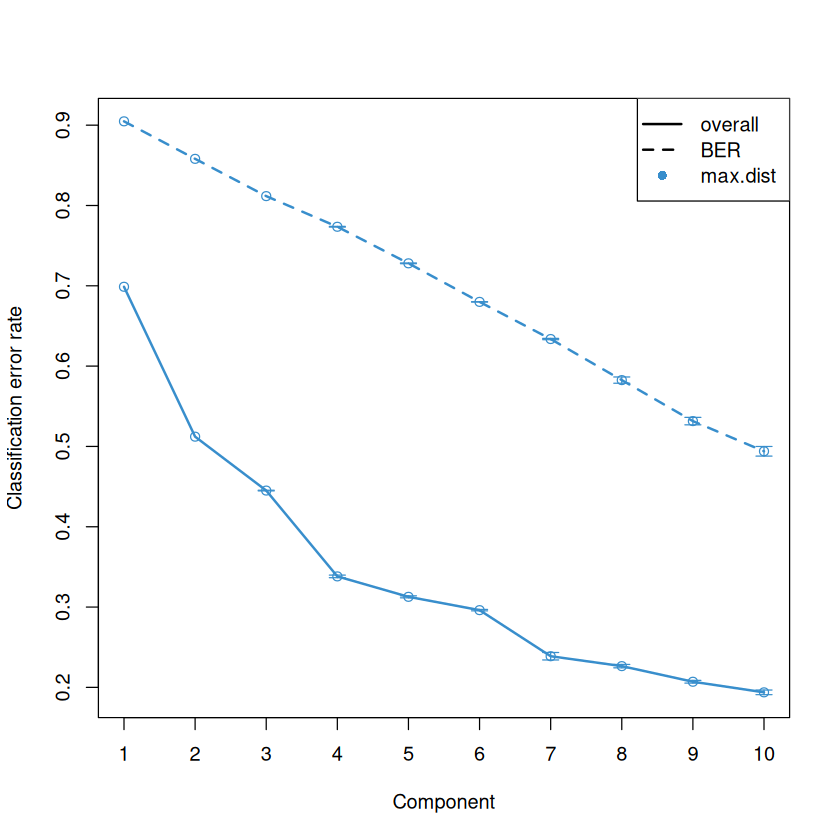

In [5]:
FOLDS      <- 5
NREPEAT    <- 10
MAX_NCOMP  <- 10   # increased from 5
KEEP_X     <- 200  # number of features to keep per component
DIST       <- "max.dist"
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

gex_prelim <- splsda(X_gex_train, Y_train,
                     ncomp = MAX_NCOMP,
                     keepX = rep(KEEP_X, MAX_NCOMP))
gex_perf   <- perf(gex_prelim,
                   validation  = "Mfold",
                   folds       = FOLDS,
                   nrepeat     = NREPEAT,
                   dist        = DIST,
                   BPPARAM     = bpparam,
                   progressBar = FALSE)

# Plot BER across all components to see the curve shape
plot(gex_perf, criterion = "BER")

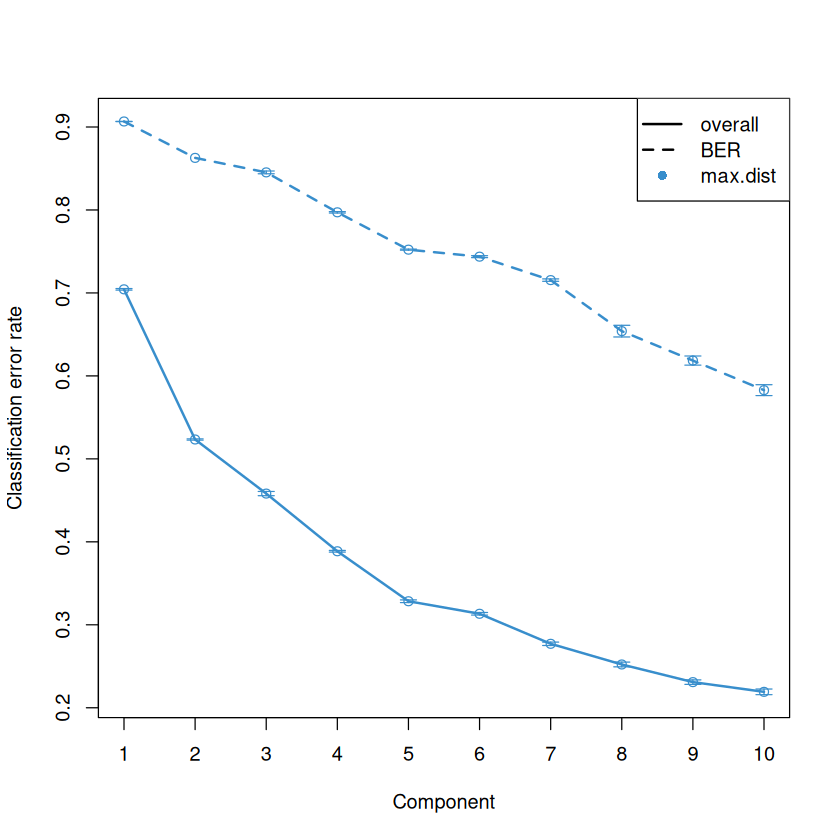

In [6]:
# ============================================================
# DNAm
# ============================================================
dnam_prelim <- splsda(X_dnam_train, Y_train,
                      ncomp = MAX_NCOMP,
                      keepX = rep(KEEP_X, MAX_NCOMP))
dnam_perf   <- perf(dnam_prelim,
                    validation  = "Mfold",
                    folds       = FOLDS,
                    nrepeat     = NREPEAT,
                    dist        = DIST,
                    BPPARAM     = bpparam,
                    progressBar = FALSE)
plot(dnam_perf, criterion = "BER")

Design matrix has changed to include Y; each block will be
            linked to Y.



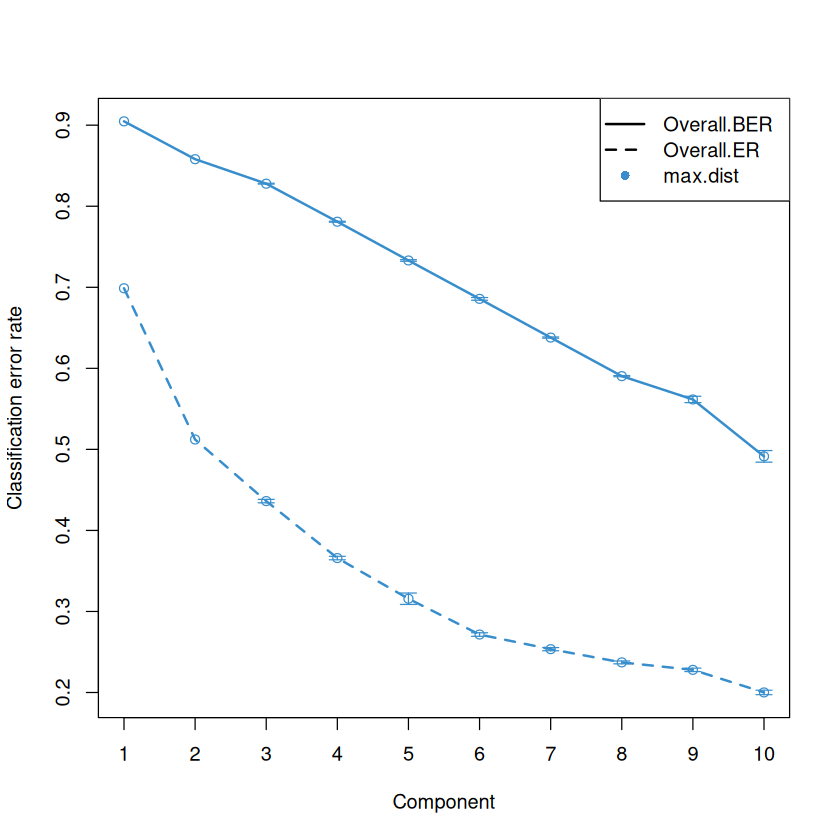

In [7]:
# ============================================================
# DIABLO
# ============================================================
design       <- matrix(0.1, nrow = 2, ncol = 2,
                       dimnames = list(c("GEX","DNAm"), c("GEX","DNAm")))
diag(design) <- 0

blocks_train <- list(GEX = X_gex_train, DNAm = X_dnam_train)

diablo_prelim <- block.splsda(X      = blocks_train,
                               Y      = Y_train,
                               ncomp  = MAX_NCOMP,
                               keepX  = list(GEX  = rep(KEEP_X, MAX_NCOMP),
                                             DNAm = rep(KEEP_X, MAX_NCOMP)),
                               design = design)
diablo_perf   <- perf(diablo_prelim,
                      validation  = "Mfold",
                      folds       = FOLDS,
                      nrepeat     = NREPEAT,
                      dist        = DIST,
                      BPPARAM     = bpparam,
                      progressBar = FALSE)
plot(diablo_perf, criterion = "BER")

In [8]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- gex_perf$choice.ncomp["BER", "max.dist"]
ncomp_dnam   <- dnam_perf$choice.ncomp["BER", "max.dist"]
ncomp_diablo <- diablo_perf$choice.ncomp$WeightedVote["Overall.BER", 1]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

Optimal ncomp — GEX: 10  DNAm: 10  DIABLO: 10 


In [9]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(gex_perf$error.rate$BER[, "max.dist"], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(dnam_perf$error.rate$BER[, "max.dist"], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(diablo_perf$WeightedVote.error.rate$max.dist)
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 
 0.905  0.858  0.812  0.773  0.728  0.680  0.634  0.583  0.532  0.494 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 
 0.907  0.863  0.845  0.797  0.752  0.744  0.715  0.654  0.618  0.583 

=== DIABLO BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 
 0.896  0.843  0.811  0.763  0.715  0.668  0.621  0.575  0.547  0.479 


In [10]:
# Check your class distribution
table(Y_train)
nlevels(Y_train)

# Random chance BER
cat("Random BER:", round(1 - 1/nlevels(Y_train), 3), "\n")

Y_train
      AML, APL-PML::RARA      AML, CBFA2T3::GLIS2         AML, CBFB::MYH11 
                      14                       13                       82 
           AML, CEBPAalt         AML, DEK::NUP214             AML, KMT2A-r 
                      71                       27                      302 
            AML, NPM1alt             AML, NUP98-r      AML, RUNX1::RUNX1T1 
                     166                       30                      220 
        B-ALL, BCR::ABL1            B-ALL, DUX4-r       B-ALL, ETV6::RUNX1 
                      10                       19                       31 
 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid            B-ALL, iAMP21 
                      10                       45                       15 
          B-ALL, KMT2A-r           B-ALL, PAX5alt        B-ALL, TCF3::PBX1 
                      13                       29                       10 
         B-ALL, ZNF384-r             Non-leukemic                    T-ALL 
    

[1] 21

Random BER: 0.952 


In [11]:
# Check if sample IDs align
all(rownames(X_gex_train) == names(Y_train))  # should be TRUE


[1] TRUE

In [12]:
# Are your matrices numeric?
str(X_gex_train[1:3, 1:3])

# Any NAs?
cat("NAs in GEX: ",  sum(is.na(X_gex_train)),  "\n")
cat("NAs in DNAm:", sum(is.na(X_dnam_train)), "\n")

# Is Y correctly a factor with the right labels?
str(Y_train)
table(Y_train)

# Are rows actually aligned between X and Y?
head(rownames(X_gex_train))
head(names(Y_train))

 num [1:3, 1:3] 14.26 20.25 -1.59 15.16 20.42 ...
 - attr(*, "dimnames")=List of 2
  ..$ : chr [1:3] "ALL_1019" "ALL_1023" "ALL_1026"
  ..$ : chr [1:3] "ENSG00000133958" "ENSG00000198010" "ENSG00000183117"


NAs in GEX:  0 
NAs in DNAm: 0 
 Factor w/ 21 levels "AML, APL-PML::RARA",..: 19 12 17 10 13 13 12 17 18 18 ...


Y_train
      AML, APL-PML::RARA      AML, CBFA2T3::GLIS2         AML, CBFB::MYH11 
                      14                       13                       82 
           AML, CEBPAalt         AML, DEK::NUP214             AML, KMT2A-r 
                      71                       27                      302 
            AML, NPM1alt             AML, NUP98-r      AML, RUNX1::RUNX1T1 
                     166                       30                      220 
        B-ALL, BCR::ABL1            B-ALL, DUX4-r       B-ALL, ETV6::RUNX1 
                      10                       19                       31 
 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid            B-ALL, iAMP21 
                      10                       45                       15 
          B-ALL, KMT2A-r           B-ALL, PAX5alt        B-ALL, TCF3::PBX1 
                      13                       29                       10 
         B-ALL, ZNF384-r             Non-leukemic                    T-ALL 
    

[1] "ALL_1019" "ALL_1023" "ALL_1026" "ALL_1039" "ALL_1047" "ALL_106"

NULL

In [13]:
nlevels(Y_train)
# or
length(unique(Y_train))

[1] 21

[1] 21

In [14]:
# Quick barplot
barplot(
  sort(per_class_ber, decreasing = TRUE),
  las = 2,
  ylab = "BER",
  main = "Per-class BER at comp10",
  col = ifelse(sort(per_class_ber, decreasing = TRUE) > 0.5, "red", "steelblue")
)

# Add random chance line
abline(h = 1 - 1/nlevels(Y_train), lty = 2, col = "grey50")

ERROR: Error in eval(expr, envir, enclos): object 'per_class_ber' not found
